# 02 — Análise exploratória e pré-processamento

**Responsável:** Peter (João Pedro Amorim)

Entrada: `data/raw/base_integrada_sidra.csv` (Lulu). Saída: `data/processed/base_modelagem.csv`, a base tratada que todos usam.

Etapas:
1. Auditoria: cobertura dos 1.668 municípios, duplicações, ausências e inconsistências.
2. Distribuições e gráficos do PIB e do crescimento anual.
3. Construção das variáveis com defasagem, sem uso de informação futura.
4. Teste de vazamento e publicação da base.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import preprocessamento as prep

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
FIG = root / "outputs/figuras"
FIG.mkdir(parents=True, exist_ok=True)

## 1. Auditoria da base integrada

In [2]:
bruto = prep.carregar_bruto()
print(bruto.shape)
pd.Series(prep.auditar(bruto))

(23352, 11)


linhas                                                                  23352
municipios                                                               1668
municipios_por_uf                  {'ES': 78, 'MG': 853, 'RJ': 92, 'SP': 645}
anos                                                                2010-2023
duplicatas_chave                                                            0
municipios_com_serie_incompleta                                             0
pib_nao_positivo                                                            0
vab_negativo                                                                3
vab_soma_maior_que_pib                                                      0
codigos_fora_do_sudeste                                                     0
dtype: object

Os 1.668 municípios do Sudeste (ES 78, MG 853, RJ 92, SP 645) aparecem em todos os 14 anos, sem chaves duplicadas, sem PIB nulo ou negativo e sem códigos de outras regiões. A soma dos três VAB setoriais nunca supera o PIB (a diferença é administração pública e impostos).

Há três registros com VAB setorial negativo. Eles vêm da própria publicação do IBGE (por exemplo, a indústria de Paulínia em 2012 e 2013, efeito contábil do refino) e foram mantidos.

In [3]:
bruto[(bruto[["vab_agro_mil_reais", "vab_industria_mil_reais", "vab_servicos_mil_reais"]] < 0).any(axis=1)][
    ["municipio", "uf", "ano", "pib_mil_reais", "vab_agro_mil_reais", "vab_industria_mil_reais"]]

,municipio,uf,ano,pib_mil_reais,vab_agro_mil_reais,vab_industria_mil_reais
20064,Paulínia,SP,2012,8.461729e+06,17523.536,-1664761.324
20065,Paulínia,SP,2013,1.098479e+07,20849.280,-1248110.905
22685,Taquaral,SP,2015,2.661392e+04,-2298.910,1154.193


### Valores ausentes por ano (%)

In [4]:
cols = [c for c in bruto.columns if c not in ("codigo_municipio", "ano", "municipio", "uf")]
ausentes = bruto[cols].isna().groupby(bruto["ano"]).mean().mul(100).round(1)
ausentes

,pib_mil_reais,vab_agro_mil_reais,vab_industria_mil_reais,vab_servicos_mil_reais,producao_agricola_mil_reais,rebanho_bovino_cabecas,populacao_estimada
ano,,,,,,,
2010,0.0,0.0,0.0,0.0,3.4,2.4,100.0
2011,0.0,0.0,0.0,0.0,3.4,2.2,0.0
2012,0.0,0.0,0.0,0.0,3.1,2.2,0.0
2013,0.0,0.0,0.0,0.0,3.3,2.4,0.0
2014,0.0,0.0,0.0,0.0,3.7,2.5,0.0
2015,0.0,0.0,0.0,0.0,3.4,2.3,0.0
2016,0.0,0.0,0.0,0.0,3.1,2.2,0.0
2017,0.0,0.0,0.0,0.0,2.8,1.9,0.0
2018,0.0,0.0,0.0,0.0,2.9,1.9,0.0


As lacunas são estruturais, não aleatórias:
- **VAB setorial**: ausente em 2022 e 2023 (abertura setorial não divulgada nesta edição).
- **População estimada**: ausente em 2010, 2022 e 2023 (2022 é ano de Censo, sem série de estimativas comparável).
- **Produção agrícola e rebanho**: cerca de 3% de ausência em todos os anos; são municípios sem registro da atividade na PAM/PPM.

Consequência para o pré-processamento: o VAB e a população entram como *último valor conhecido até t-1*, acompanhados da defasagem em anos; a ausência agropecuária ganha indicador binário.

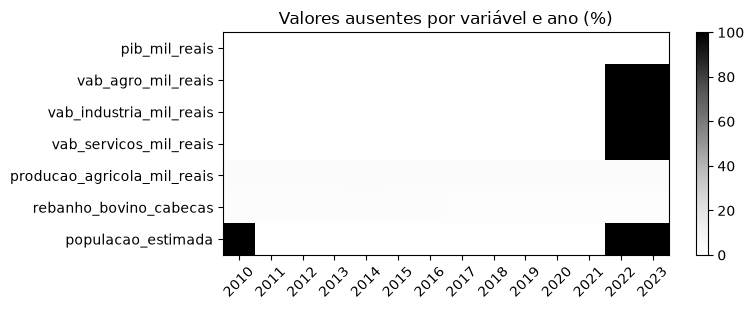

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(ausentes.T.values, aspect="auto", cmap="Greys", vmin=0, vmax=100)
ax.set_xticks(range(len(ausentes.index)), ausentes.index, rotation=45)
ax.set_yticks(range(len(cols)), cols)
ax.set_title("Valores ausentes por variável e ano (%)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

## 2. Distribuições

In [6]:
bruto.groupby("ano")["pib_mil_reais"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
ano,,,,,,,,
2010,1668.0,1307547.0,12610839.0,9628.0,42336.0,112182.0,387050.0,4.504920e+08
2011,1668.0,1472147.0,14034630.0,10781.0,48510.0,130193.0,451645.0,5.019644e+08
2012,1668.0,1614539.0,15155743.0,11882.0,54975.0,145713.0,493375.0,5.388771e+08
2013,1668.0,1767832.0,16486696.0,14097.0,60100.0,156198.0,535795.0,5.820797e+08
2014,1668.0,1903292.0,17568958.0,15306.0,65157.0,175024.0,596789.0,6.219174e+08
2015,1668.0,1941689.0,18437319.0,16599.0,69301.0,183109.0,633784.0,6.536470e+08
2016,1668.0,1998341.0,19195044.0,17912.0,78513.0,203741.0,664267.0,6.830667e+08
2017,1668.0,2087616.0,19662086.0,17477.0,80160.0,210732.0,708597.0,6.989522e+08
2018,1668.0,2231005.0,20360134.0,18121.0,81212.0,210187.0,707166.0,7.146636e+08


In [7]:
crescimento = bruto.groupby("codigo_municipio")["pib_mil_reais"].pct_change().mul(100)
bruto["variacao_pib_pct"] = crescimento
print(crescimento.describe().round(2))
print("Quantis:\n", crescimento.quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(2))

count    21684.00
mean        10.62
std         23.25
min        -90.16
25%          2.89
50%          8.87
75%         15.58
max       1408.39
Name: pib_mil_reais, dtype: float64
Quantis:
 0.01   -30.33
0.05    -9.77
0.50     8.87
0.95    34.10
0.99    68.53
Name: pib_mil_reais, dtype: float64


O PIB municipal é extremamente assimétrico: a mediana fica perto de R$ 200 milhões, enquanto São Paulo passa de R$ 1 trilhão. Na escala logarítmica a distribuição fica próxima de simétrica, por isso os modelos usam log do PIB.

O crescimento nominal anual tem mediana em torno de 9%, mas caudas longas (de -90% a mais de +1.400%), concentradas em municípios pequenos e dependentes de uma atividade (mineração, petróleo, usinas). Esses casos foram mantidos: são valores oficiais e o modelo precisa lidar com eles; o MAPE é sensível a eles.

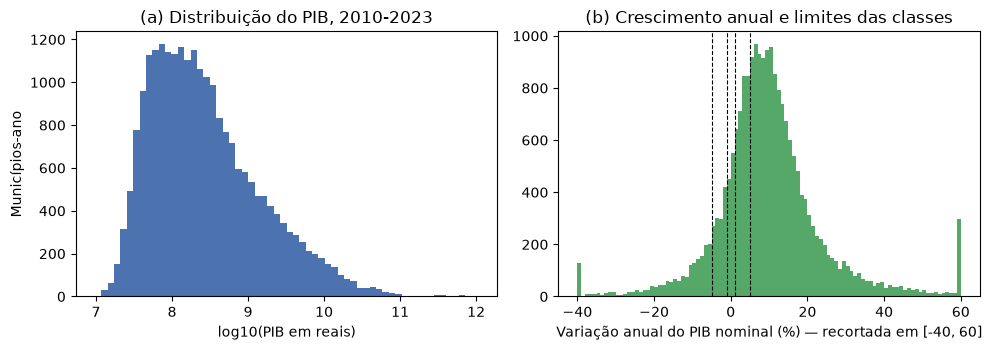

In [8]:
LIMITES = [-5, -1, 1, 5]  # limites das classes do enunciado (definidas pela Amanda)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(np.log10(bruto["pib_mil_reais"] * 1000), bins=60, color="#4C72B0")
axes[0].set_xlabel("log10(PIB em reais)")
axes[0].set_ylabel("Municípios-ano")
axes[0].set_title("(a) Distribuição do PIB, 2010-2023")

v = crescimento.dropna().clip(-40, 60)
axes[1].hist(v, bins=100, color="#55A868")
for lim in LIMITES:
    axes[1].axvline(lim, color="black", lw=0.8, ls="--")
axes[1].set_xlabel("Variação anual do PIB nominal (%) — recortada em [-40, 60]")
axes[1].set_title("(b) Crescimento anual e limites das classes")
fig.tight_layout()
fig.savefig(FIG / "fig_eda_distribuicoes.png", dpi=200)
plt.show()

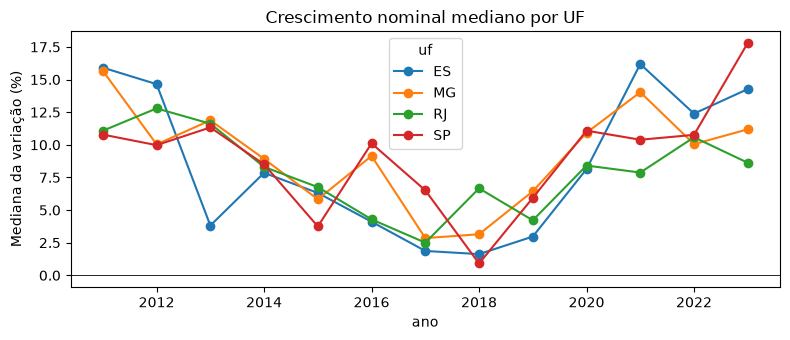

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
(bruto.groupby(["ano", "uf"])["variacao_pib_pct"].median().unstack()).plot(ax=ax, marker="o")
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Mediana da variação (%)")
ax.set_title("Crescimento nominal mediano por UF")
fig.tight_layout()
plt.show()

O crescimento é fortemente sincronizado entre municípios e estados (queda em 2015-2016 e 2020, salto em 2021-2022 com a inflação). Isso justifica incluir a mediana estadual do crescimento em t-1 como variável de contexto macro.

In [10]:
cats = pd.cut(crescimento, [-np.inf, -5, -1, 1, 5, np.inf], right=False,
              labels=["forte retração", "retração", "estabilidade", "cresc. moderado", "forte crescimento"])
pd.crosstab(bruto["ano"], cats, normalize="index").mul(100).round(1)

pib_mil_reais,forte retração,retração,estabilidade,cresc. moderado,forte crescimento
ano,,,,,
2011,4.9,2.5,2.2,7.9,82.6
2012,8.2,4.7,3.6,10.7,72.8
2013,7.3,3.7,3.2,10.2,75.7
2014,6.1,5.2,5.4,14.1,69.1
2015,13.3,9.1,5.9,22.1,49.6
2016,9.0,4.2,4.1,14.2,68.5
2017,14.7,10.7,8.3,20.2,46.1
2018,17.6,13.2,9.3,25.2,34.7
2019,9.4,8.3,6.4,19.5,56.4


Distribuição ilustrativa nas cinco faixas do enunciado (a definição oficial das classes e dos limites é da Amanda). A classe *forte crescimento* domina quase todos os anos, porque o PIB é nominal; as classes estão desbalanceadas.

In [11]:
corr = bruto.assign(
    log_pib=np.log(bruto["pib_mil_reais"]),
    log_pop=np.log(bruto["populacao_estimada"]),
    log_agri=np.log1p(bruto["producao_agricola_mil_reais"]),
    log_rebanho=np.log1p(bruto["rebanho_bovino_cabecas"]),
)[["log_pib", "log_pop", "log_agri", "log_rebanho"]].corr().round(2)
corr

,log_pib,log_pop,log_agri,log_rebanho
log_pib,1.00,0.93,0.31,0.01
log_pop,0.93,1.00,0.20,0.04
log_agri,0.31,0.20,1.00,0.23
log_rebanho,0.01,0.04,0.23,1.00


## 3. Construção da base de modelagem

Regras (implementadas em `preprocessamento.py`):

| Etapa | Tratamento |
| --- | --- |
| Granularidade | Uma linha por município e ano-alvo t, de 2011 a 2024 (2024 = linha de previsão, alvo vazio). |
| Defasagens | Toda variável explicativa usa anos ≤ t-1: log do PIB em t-1 e t-2, crescimento em t-1 e t-2, mediana estadual do crescimento em t-1. |
| Transformações | log do PIB e da população; `log(1+x)` para produção agrícola e rebanho; VAB convertido em participação no PIB. |
| Lacunas estruturais | VAB e população: último valor conhecido até t-1 (*forward fill* só do passado) + defasagem em anos. |
| Lacunas agropecuárias | Mantidas como NaN na base, com indicadores binários `sem_*`; imputação pela mediana dentro do pipeline, ajustada só no treino. |
| Codificação | UF em *one-hot* dentro do pipeline. |
| Escala | `StandardScaler` opcional no pipeline (`criar_preprocessador(escalonar=True)`) para modelos lineares/logísticos; ajustado só no treino. |
| Alvos | `pib_mil_reais` (nível), `log_razao_pib` = log(PIB_t / PIB_t-1) e `variacao_pib_pct` (base das classes). |

Imputação e escala não são aplicadas no CSV para não usar estatísticas de anos futuros: elas ficam no pipeline e são ajustadas somente nas linhas de treino de cada corte.

In [12]:
base = prep.construir_base(bruto.drop(columns="variacao_pib_pct"))
print(base.shape)
base[base["codigo_municipio"] == 3550308].tail(4).T

(23352, 26)


,22200,22201,22202,22203
codigo_municipio,3550308,3550308,3550308,3550308
municipio,São Paulo,São Paulo,São Paulo,São Paulo
uf,SP,SP,SP,SP
ano,2021,2022,2023,2024
pib_mil_reais,828980746.586,945946482.808,1066825104.983,NaN
pib_lag1_mil_reais,746909329.587,828980746.586,945946482.808,1066825104.983
log_pib_lag1,20.431454,20.535707,20.667697,20.787953
log_pib_lag2,20.453552,20.431454,20.535707,20.667697
cresc_pib_lag1,-0.022097,0.104253,0.131989,0.120256
cresc_pib_lag2,0.066229,-0.022097,0.104253,0.131989


In [13]:
base[prep.FEATURES_NUMERICAS].isna().groupby(base["ano"]).sum().loc[[2011, 2012, 2022, 2023, 2024]]

,log_pib_lag1,log_pib_lag2,cresc_pib_lag1,cresc_pib_lag2,cresc_pib_mediana_uf_lag1,part_agro_ult,part_industria_ult,part_servicos_ult,defasagem_vab,log_populacao_ult,defasagem_populacao,log_pib_per_capita_lag1,log_producao_agricola_lag1,cresc_producao_agricola_lag1,log_rebanho_bovino_lag1,sem_producao_agricola_lag1,sem_rebanho_bovino_lag1
ano,,,,,,,,,,,,,,,,,
2011,0,1668,1668,1668,1668,0,0,0,0,1668,1668,1668,57,1668,40,0,0
2012,0,0,0,1668,0,0,0,0,0,0,0,0,56,60,37,0,0
2022,0,0,0,0,0,0,0,0,0,0,0,0,48,53,31,0,0
2023,0,0,0,0,0,0,0,0,0,0,0,0,49,50,30,0,0
2024,0,0,0,0,0,0,0,0,0,0,0,0,54,54,30,0,0


## 4. Teste de vazamento e publicação

In [14]:
# Se a base fosse construída sem os dados do ano t, as variáveis do ano t teriam de ser idênticas.
for t in (2022, 2023):
    sem_t = prep.construir_base(bruto[bruto["ano"] < t].drop(columns="variacao_pib_pct"))
    a = base[base["ano"] == t].set_index("codigo_municipio")[prep.FEATURES_NUMERICAS]
    b = sem_t[sem_t["ano"] == t].set_index("codigo_municipio")[prep.FEATURES_NUMERICAS]
    assert np.allclose(a.fillna(-999).values, b.fillna(-999).values)
    print(f"{t}: variáveis idênticas sem os dados de {t} -> sem vazamento")

2022: variáveis idênticas sem os dados de 2022 -> sem vazamento
2023: variáveis idênticas sem os dados de 2023 -> sem vazamento


In [15]:
assert base.duplicated(["codigo_municipio", "ano"]).sum() == 0
assert base.groupby("ano")["codigo_municipio"].nunique().eq(1668).all()
prep.SAIDA.parent.mkdir(parents=True, exist_ok=True)
base.to_csv(prep.SAIDA, index=False, encoding="utf-8", float_format="%.6f")
print(prep.SAIDA.relative_to(root), base.shape)

data\processed\base_modelagem.csv (23352, 26)


**Como usar a base:** filtrar `ano <= corte` para treino; `ano == 2023` para validação; `conjunto == "previsao"` (ano 2024) para a entrega. O preprocessador recomendado é `prep.criar_preprocessador()` dentro de um `sklearn.pipeline.Pipeline`.